In [1]:
#DỰ ĐOÁN KHÁCH HÀNG RỜI MẠNG (TELCO CUSTOMER CHURN)
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()
#nhìn 5 hàng đầu và xem đúng số khách hàng và số cột

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()
#xem dữ liệu đúng kiểu dữ liệu chưa

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df.isna().sum()
#đếm số ô rỗng

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isna().sum()
#ở trên thấy 11 ô total charges rỗng
#Dòng đầu ép cột về kiểu số, ô nào không chuyển được (ví dụ chuỗi chỉ có dấu cách) sẽ thành NaN nhờ errors="coerce"


np.int64(11)

In [5]:
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]
#check 11 dòng đấy là của ai

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [6]:
df["Churn"].value_counts()
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


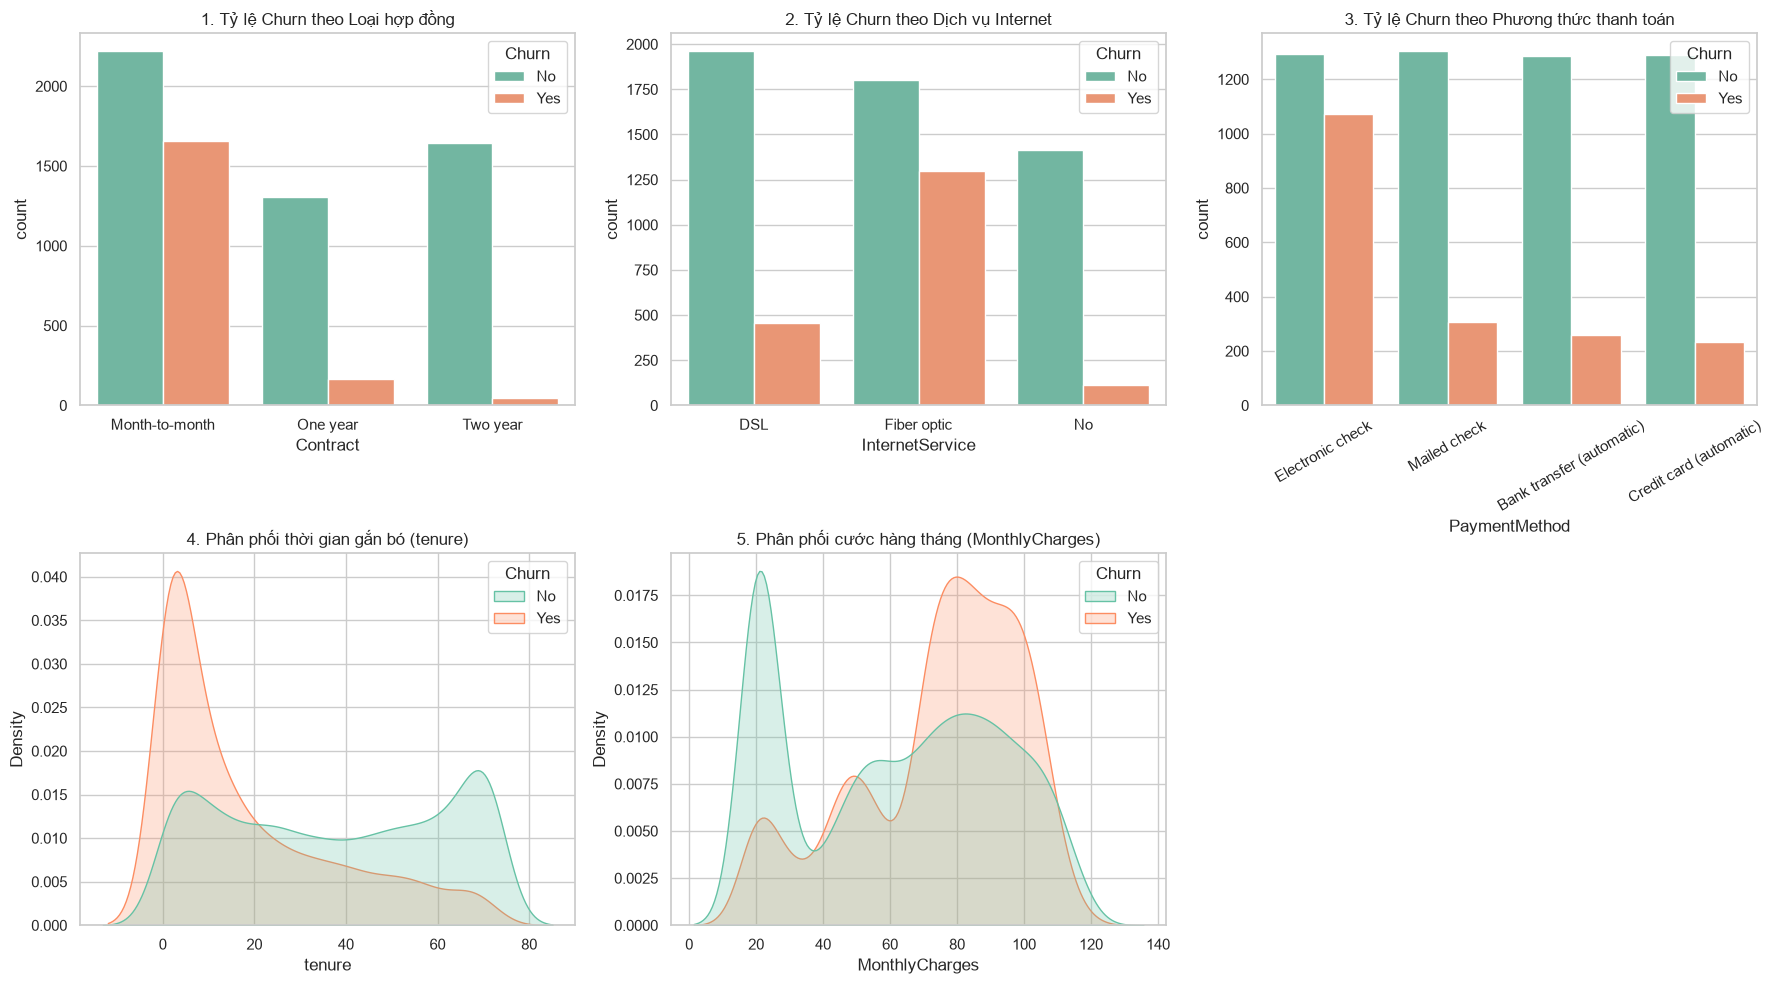

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện biểu đồ
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Contract vs Churn
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("1. Tỷ lệ Churn theo Loại hợp đồng")

# 2. InternetService vs Churn
sns.countplot(data=df, x="InternetService", hue="Churn", ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title("2. Tỷ lệ Churn theo Dịch vụ Internet")

# 3. PaymentMethod vs Churn
sns.countplot(data=df, x="PaymentMethod", hue="Churn", ax=axes[0, 2], palette="Set2")
axes[0, 2].set_title("3. Tỷ lệ Churn theo Phương thức thanh toán")
axes[0, 2].tick_params(axis='x', rotation=30)

# 4. Tenure (Số tháng gắn bó) vs Churn
sns.kdeplot(data=df, x="tenure", hue="Churn", common_norm=False, fill=True, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("4. Phân phối thời gian gắn bó (tenure)")

# 5. MonthlyCharges (Cước tháng) vs Churn
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", common_norm=False, fill=True, ax=axes[1, 1], palette="Set2")
axes[1, 1].set_title("5. Phân phối cước hàng tháng (MonthlyCharges)")

# Ẩn ô biểu đồ thừa thứ 6
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

In [9]:
# 1. Ép kiểu TotalCharges sang số và điền 0 cho 11 giá trị bị rỗng
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# 2. Chuyển đổi cột mục tiêu Churn thành dạng số (1: Churn, 0: Không Churn)
y = df["Churn"].map({"Yes": 1, "No": 0})

# 3. Tạo tập đặc trưng X bằng cách bỏ cột customerID và Churn
X = df.drop(columns=["customerID", "Churn"])

print("Kích thước ma trận đặc trưng X:", X.shape)
print("Số lượng nhãn 0 và 1:\n", y.value_counts())

Kích thước ma trận đặc trưng X: (7043, 19)
Số lượng nhãn 0 và 1:
 Churn
0    5174
1    1869
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

# Chia tập dữ liệu thành Train (80%) và Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)
print("\nTỷ lệ Churn trên tập Train:\n", y_train.value_counts(normalize=True))
print("\nTỷ lệ Churn trên tập Test:\n", y_test.value_counts(normalize=True))

Kích thước X_train: (5634, 19)
Kích thước X_test: (1409, 19)

Tỷ lệ Churn trên tập Train:
 Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Tỷ lệ Churn trên tập Test:
 Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Phân loại cột số và cột chữ (categorical)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [col for col in X_train.columns if col not in num_cols]

# 2. Định nghĩa bộ biến đổi (Pipeline biến đổi dữ liệu)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols)
    ]
)

# 3. FIT + TRANSFORM trên tập Train, nhưng CHỈ TRANSFORM trên tập Test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 4. Lấy lại tên cột để chuyển thành DataFrame
feature_names = preprocessor.get_feature_names_out()
X_train_processed = pd.DataFrame(X_train_processed, columns=feature_names)
X_test_processed = pd.DataFrame(X_test_processed, columns=feature_names)

print("Số lượng đặc trưng sau khi One-Hot Encoding:", len(feature_names))
X_train_processed.head(3)

Số lượng đặc trưng sau khi One-Hot Encoding: 30


,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Male,cat__SeniorCitizen_1,cat__Partner_Yes,cat__Dependents_Yes,cat__PhoneService_Yes,cat__MultipleLines_No phone service,cat__MultipleLines_Yes,...,cat__StreamingTV_No internet service,cat__StreamingTV_Yes,cat__StreamingMovies_No internet service,cat__StreamingMovies_Yes,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_Yes,cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
0,0.102371,-0.521976,-0.262257,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.711743,0.337478,-0.503635,1.0,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-0.793155,-0.809013,-0.749883,1.0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Khai báo 3 mô hình cơ bản
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# 2. Huấn luyện từng mô hình và đo đạc kết quả trên tập Test
results = []
for name, model in models.items():
    # Huấn luyện trên tập Train
    model.fit(X_train_processed, y_train)
    
    # Dự đoán nhãn (0 hoặc 1) và dự đoán xác suất trên tập Test
    y_pred = model.predict(X_test_processed)
    y_proba = model.predict_proba(X_test_processed)[:, 1]
    
    # Lưu lại toàn bộ các chỉ số đo lường
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

# 3. Hiển thị bảng tổng kết so sánh
df_results = pd.DataFrame(results)
df_results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8062,0.6593,0.5588,0.6049,0.8422
1,Decision Tree,0.7317,0.4946,0.4866,0.4906,0.6530
2,Random Forest,0.7921,0.6421,0.4893,0.5554,0.8275


In [13]:
# Huấn luyện lại Logistic Regression nhưng có thêm class_weight='balanced'
model_balanced = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model_balanced.fit(X_train_processed, y_train)

# Đánh giá lại kết quả
y_pred_bal = model_balanced.predict(X_test_processed)
print("Recall MỚI:", round(recall_score(y_test, y_pred_bal), 4))
print("Accuracy MỚI:", round(accuracy_score(y_test, y_pred_bal), 4))

Recall MỚI: 0.7834
Accuracy MỚI: 0.7381


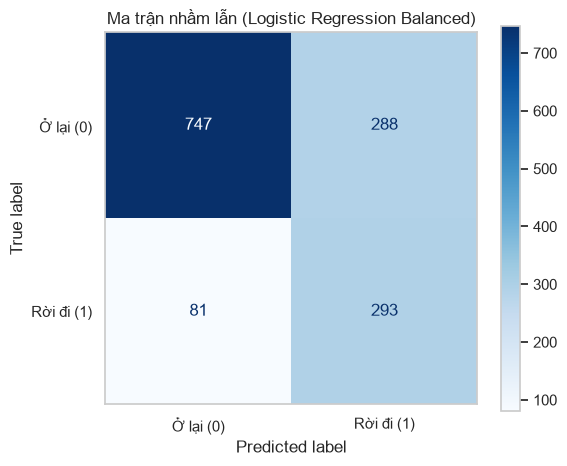

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Vẽ ma trận nhầm lẫn cho mô hình Logistic Regression sau khi cân bằng
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_bal, 
    display_labels=["Ở lại (0)", "Rời đi (1)"],
    cmap="Blues", 
    ax=ax
)
plt.title("Ma trận nhầm lẫn (Logistic Regression Balanced)")
plt.grid(False) # Tắt đường kẻ mờ để nhìn số rõ hơn
plt.show()

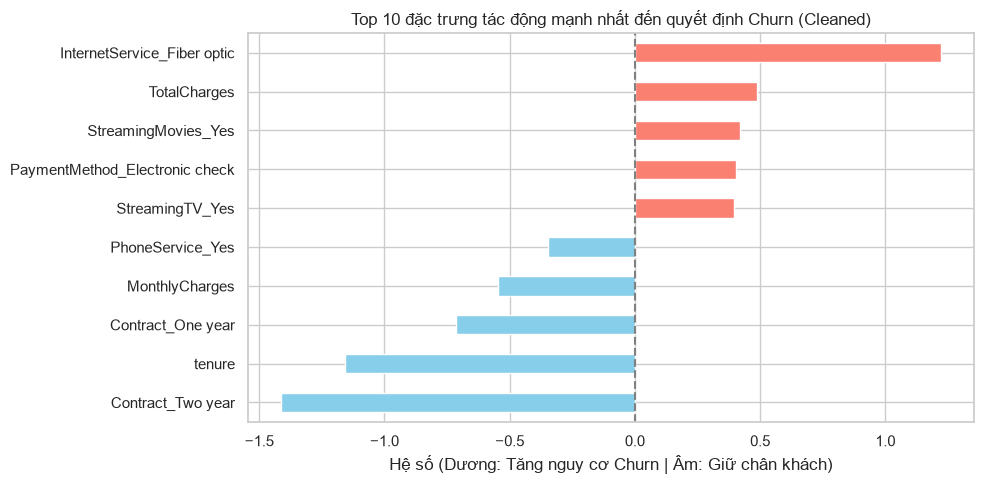

In [15]:
# 1. Làm sạch tên cột: Bỏ tiền tố 'cat__' và 'num__'
clean_feature_names = [col.replace("cat__", "").replace("num__", "") for col in feature_names]

# 2. Gán lại hệ số với tên cột đã làm sạch
weights = pd.Series(model_balanced.coef_[0], index=clean_feature_names)

# 3. Lấy Top 5 yếu tố kéo khách ở lại và Top 5 yếu tố đẩy khách đi
top_features = pd.concat([weights.nlargest(5), weights.nsmallest(5)]).sort_values()

# 4. Vẽ biểu đồ thanh ngang
plt.figure(figsize=(10, 5))
top_features.plot(kind="barh", color=(top_features > 0).map({True: "salmon", False: "skyblue"}))
plt.title("Top 10 đặc trưng tác động mạnh nhất đến quyết định Churn (Cleaned)")
plt.xlabel("Hệ số (Dương: Tăng nguy cơ Churn | Âm: Giữ chân khách)")
plt.axvline(0, color="grey", linestyle="--")
plt.tight_layout()
plt.show()